# ATML2021 Assignment 2 [Seyedeh Sharareh Mirzargar]

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt

import time

import torch
import torch.nn as nn
import numpy as np
import random
import matplotlib.pyplot as plt
from PIL import Image
from tqdm import tqdm

import os
import cv2 # pip install opencv-python
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("you are running on "+str(device))

you are running on cuda


# 1. Train a convolutional neural network for binary classification
Your network will learn to classify 48x48 patches into two classes: noface/face. Instructions in the pdf.

##Preparing the data

**As the size of the dataset is high, and google colab recycles the uploaded datasets, after each run; I decided to upload the dataset to my google drive once and unzip it from that directory**

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


 Unzip the given dataset in the current directory. **Please edit the path to your folder contatning: Assignment2_data.zip**

In [ ]:
!unzip "/content/drive/MyDrive/Assignment2_data.zip"

Convert images to Tensors

In [4]:
from torchvision.datasets import ImageFolder
from torchvision.transforms import Resize, ToTensor, Normalize, Compose
root_dir = "/content/"

tsk1_transforms = Compose([ToTensor(),           # Converts to Tensor, scales to [0, 1] float (from [0, 255] int)
                    Normalize(mean=(0.5, 0.5, 0.5,), std=(0.5, 0.5, 0.5)), # scales to [-1.0, 1.0]
                    ])

train_dataset = ImageFolder(root_dir+"train", transform=tsk1_transforms)
val_dataset   = ImageFolder(root_dir+"val", transform=tsk1_transforms)

In [5]:
print("train dataset size is:"+str(len(train_dataset)))
print("validation dataset size is:"+str(len(val_dataset)))

train dataset size is:89340
validation dataset size is:10000


Loading the dataset into RAM

In [6]:
from tqdm import tqdm

class RAMDatasetWrapper(torch.utils.data.Dataset):
    def __init__(self, dataset, transform=None):
        data = []
        for sample in tqdm(dataset):
            data.append(sample)
        self.n = len(dataset)
        self.data = data
        self.transform = transform
        
    def __getitem__(self, ind):
        if self.transform is not None:
            return self.transform(self.data[ind][0]), self.data[ind][1]
        else:
            return self.data[ind]
    
    def set_tranform(self, transform):
        self.transform = transform
    
    def __len__(self):
        return self.n

In [7]:
train_dataset = RAMDatasetWrapper(train_dataset)
val_dataset = RAMDatasetWrapper(val_dataset)

100%|██████████| 10000/10000 [00:04<00:00, 2369.62it/s]


Visualize a few images
from both classes.

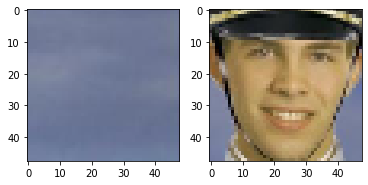

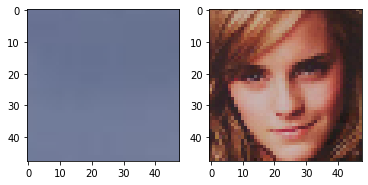

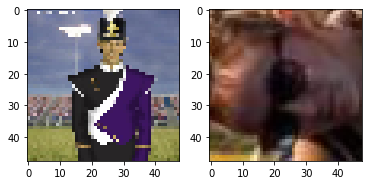

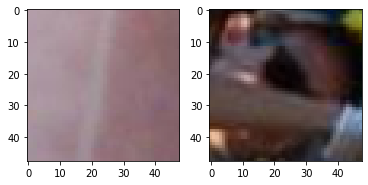

In [8]:
from PIL import Image

for i in [0,1,2,5]:
  f, axarr = plt.subplots(1,2)
  image_not_face = Image.open("/content/train/bg/00000"+str(i)+".png")
  image_face = Image.open("/content/train/face/00000"+str(i)+".png")
  axarr[0].imshow(image_not_face)
  axarr[1].imshow(image_face)

Create dataloaders

In [9]:
from torch.utils.data import DataLoader
def get_dataloaders(train_dataset, val_dataset, batch_size=32):
    train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
    val_dataloader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

    return train_dataloader, val_dataloader

In [10]:
batch_size = 64
train_dataloader, val_dataloader = get_dataloaders(train_dataset, val_dataset, batch_size=batch_size)

##Designing the model

In [11]:
class BinaryConvModel(nn.Module):
    
    def __init__(self):
          super(BinaryConvModel, self).__init__()
          self.conv_layers = nn.Sequential(
              # input size: 3x48x48
              nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, stride=1, padding=0),
              # output: 32x46x46 (because kernel_size=3 and no padding)
              nn.MaxPool2d(kernel_size=3, stride=2, ceil_mode=True),
              # output: 32x23x23
              nn.LeakyReLU(0.2),
              # input: 32x23x23
              nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=0),
              # output: 64x21x21
              nn.MaxPool2d(kernel_size=3, stride=2),
              # output: 64x10x10
              nn.LeakyReLU(0.2),
              # intput: 64x10x10
              nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3, stride=1, padding=0),
              # output: 64x8x8
              nn.MaxPool2d(kernel_size=2, stride=2),
              # output: 64x4x4
              nn.LeakyReLU(0.2),
              # intput: 64x4x4
              nn.Conv2d(in_channels=64, out_channels=128, kernel_size=2, stride=1, padding=0),
              # output: 128x3x3
              nn.LeakyReLU(0.2),
              # intput: 128x3x3
              nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, stride=1, padding=0),
              # output: 256x1x1
              nn.LeakyReLU(0.2),
              # intput: 256x1x1
              nn.Conv2d(in_channels=256, out_channels=2, kernel_size=1, stride=1, padding=0),
              # output: 2x1x1
          )
          
      
    def forward(self, input):
        output = self.conv_layers(input)
        return output

##Plotting function


In [12]:
def plot_fnc(losses_train, losses_val, accuracies_train, accuracies_val, plt_title, leg1, leg2):
    
    plt.figure()
    plt.title("Loss "+ leg1 +' v.s. '+leg2 )
    plt.plot(np.arange(len(losses_train)), losses_train)
    plt.plot(np.arange(len(losses_val)), losses_val)
    plt.legend([leg1 + '_loss', leg2 + '_loss'])
    plt.xlabel('epoch')
    plt.ylabel('loss value')
    plt.title(plt_title + ' loss')
    

    plt.figure()
    plt.title("Accuracy "+ leg1 +' v.s. '+leg2)
    plt.plot(np.arange(len(accuracies_train)), accuracies_train)
    plt.plot(np.arange(len(accuracies_val)), accuracies_val)
    plt.legend([leg1 + '_acc', leg2 + '_acc'])
    plt.xlabel('epoch')
    plt.ylabel('accuracy')
    plt.title(plt_title + ' accuracy')
    
    pass

##Training code

In [13]:
def train(model, train_loader, optimizer, loss_fn, print_every=100):
    '''
    Trains the model for one epoch
    '''
    model.train()
    losses = []
    n_correct = 0
    for iteration, (images, labels) in enumerate(train_loader):
        images = images.to(device)
        labels = labels.to(device)
        output = model(images)
        output = output.view(output.size(0),-1)
        optimizer.zero_grad()
        loss = loss_fn(output, labels)
        loss.backward()
        optimizer.step()
#         if iteration % print_every == 0:
#             print('Training iteration {}: loss {:.4f}'.format(iteration, loss.item()))
        losses.append(loss.item())
        n_correct += torch.sum(output.argmax(1) == labels).item()
    accuracy = 100.0 * n_correct / len(train_loader.dataset)
    return np.mean(np.array(losses)), accuracy

##Testing code

In [14]:
def test(model, test_loader, loss_fn):
    '''
    Tests the model on data from test_loader
    '''
    model.eval()
    test_loss = 0
    n_correct = 0
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)
            output = model(images)
            output = output.view(output.size(0),-1)
            loss = loss_fn(output, labels)
            test_loss += loss.item()
            n_correct += torch.sum(output.argmax(1) == labels).item()

    average_loss = test_loss / len(test_loader)
    accuracy = 100.0 * n_correct / len(test_loader.dataset)
#     print('Test average loss: {:.4f}, accuracy: {:.3f}'.format(average_loss, accuracy))
    return average_loss, accuracy

##Fit function

In [15]:
def fit(train_dataloader, val_dataloader, model, optimizer, loss_fn, n_epochs, scheduler=None):
    train_losses, train_accuracies = [], []
    val_losses, val_accuracies = [], []

    for epoch in range(n_epochs):
        train_loss, train_accuracy = train(model, train_dataloader, optimizer, loss_fn)
        val_loss, val_accuracy = test(model, val_dataloader, loss_fn)
        train_losses.append(train_loss)
        train_accuracies.append(train_accuracy)
        val_losses.append(val_loss)
        val_accuracies.append(val_accuracy)
        if scheduler:
            scheduler.step() # argument only needed for ReduceLROnPlateau
        print('Epoch {}/{}: train_loss: {:.4f}, train_accuracy: {:.4f}, val_loss: {:.4f}, val_accuracy: {:.4f}'.format(epoch+1, n_epochs,
                                                                                                          train_losses[-1],
                                                                                                          train_accuracies[-1],
                                                                                                          val_losses[-1],
                                                                                                          val_accuracies[-1]))
    
    return train_losses, train_accuracies, val_losses, val_accuracies

##Train and validation

In [16]:
model_binary_conv = BinaryConvModel()
model_binary_conv = model_binary_conv.to(device)
learning_rate = 3e-4
optimizer = torch.optim.Adam(model_binary_conv.parameters(), lr=learning_rate)
n_epochs = 10
loss_fn = nn.CrossEntropyLoss()
Start = time.time()
train_losses, train_accuracies, val_losses, val_accuracies = fit(train_dataloader, val_dataloader, model_binary_conv, optimizer, loss_fn, n_epochs)
End = time.time()
print("run time is={:f}".format(End-Start))

Epoch 1/10: train_loss: 0.2389, train_accuracy: 90.3224, val_loss: 0.1746, val_accuracy: 93.3100
Epoch 2/10: train_loss: 0.1636, train_accuracy: 93.7430, val_loss: 0.1578, val_accuracy: 93.8200
Epoch 3/10: train_loss: 0.1430, train_accuracy: 94.6094, val_loss: 0.1366, val_accuracy: 95.0000
Epoch 4/10: train_loss: 0.1277, train_accuracy: 95.1992, val_loss: 0.1296, val_accuracy: 95.0100
Epoch 5/10: train_loss: 0.1176, train_accuracy: 95.6257, val_loss: 0.1443, val_accuracy: 94.2900
Epoch 6/10: train_loss: 0.1088, train_accuracy: 95.9078, val_loss: 0.1273, val_accuracy: 94.9800
Epoch 7/10: train_loss: 0.1005, train_accuracy: 96.1854, val_loss: 0.1225, val_accuracy: 95.2700
Epoch 8/10: train_loss: 0.0930, train_accuracy: 96.5122, val_loss: 0.1177, val_accuracy: 95.5900
Epoch 9/10: train_loss: 0.0847, train_accuracy: 96.8581, val_loss: 0.1276, val_accuracy: 95.5100
Epoch 10/10: train_loss: 0.0779, train_accuracy: 97.0439, val_loss: 0.1296, val_accuracy: 95.4800
run time is=120.203352


Saving the model for using it in task 2

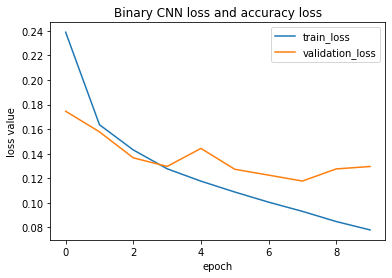

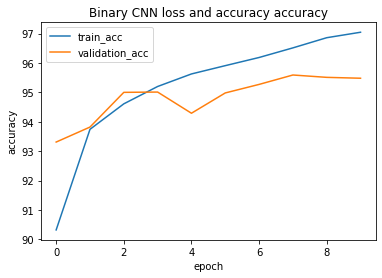

In [17]:
plot_fnc(train_losses, val_losses, train_accuracies, val_accuracies,"Binary CNN loss and accuracy","train","validation")
torch.save(model_binary_conv.state_dict(), 'model_tmp.ckpt')
torch.save(model_binary_conv.state_dict(), 'model.ckpt')


# 2. Implement fully convolutional face detector that uses the binary classifier
Use your trained binary classification model for face detection in bigger images.  
Follow the instructions in the pdf and in the comments 

In [18]:
import torchvision.transforms as transforms
from nms import nms

class FullyConvolutionalDetector:
    def __init__(self, model, max_res=1024, scales=[1.0, 0.8, 0.6, 0.4, 0.2, 0.1], threshold=0.5):
        self.model = model
        self.max_res = max_res
        self.scales = scales
        self.threshold = threshold
    
    @torch.no_grad()
    def detect_single_scale(self, image):
        '''Run a fully convolutional model on the input image'''
        '''Image is assumed to be of shape HxWx3 and scaled to [0,1]'''
        ## TODO
        ## Preprocess the image (subtract and divide as in training)
        
        

        pass
        ## Convert the image to a tensor of shape 1x3xHxW; move it to the same device as the model
        image = transforms.ToTensor()(image)
        image = transforms.Normalize(mean=(0.5, 0.5, 0.5,), std=(0.5, 0.5, 0.5))(image)
        image = image.view(1, image.size(0), image.size(1), image.size(2))
        image = image.to(device)
        
        
        H = image.size(2)
        W = image.size(3)
        
        pass
        ## Run the self.model on the image
        
        output=self.model(image)
        
        H_out = output.size(2)
        W_out = output.size(3)

        
        pass
        ## Process the output with softmax (torch.softmax) on the channel dimension
        m = nn.Softmax(dim=1)
        pr = m(output)
        pass
        ## Get probabilities for the face class (discard the non-face class)
        if(device.type == 'cuda'):
          probabilities_np_arr = pr.cpu().numpy()
        else:
          probabilities_np_arr = pr.numpy()
        #when running the model on images that surely have face the first probability is near one, therefore, I have discarded the second probability
        probabilities_np_arr = probabilities_np_arr[0,1:,:,:]
        
        pass
        ## Find output coordinates where the face probability > self.threshold
        ## (hint: you can convert output to numpy and use np.where)
        coordinates_temp = np.where(probabilities_np_arr > self.threshold)
        
        detected = len(coordinates_temp[0])
        H_out_arr = coordinates_temp[1]
        W_out_arr = coordinates_temp[2]
         
        
        pass
        ## Convert selected output coordinates to input coordinates 
        ## You should return coordinates as a numpy array of shape Nx4 (N - detected faces)
        ## each row are coordinates x1, y1, x2, y2 - top left and bottom right corner of a rectangle
        face_coordiantes = np.zeros((detected,4),dtype=int)
        face_probabilities = np.zeros(detected, dtype=float)
        for i in range(detected):

          w = W_out_arr[i]
          h = H_out_arr[i]
          

          ####Second implementation
          step_w = np.ceil ( ( W - 48 ) / W_out )
          step_h = np.ceil ( ( H - 48 ) / H_out )
          
          x1 = w * step_w
          face_coordiantes[i][0] = x1
          
          
          
          y1 = h * step_h
          face_coordiantes[i][1] = y1
          
          
          
          x2 = x1+ 47 
          face_coordiantes[i][2] = x2
          
          

          y2 = y1 + 47 
          face_coordiantes[i][3] = y2



         
          face_probabilities[i] = probabilities_np_arr[0,h,w]

        pass
        ## Return face coordinates and their probabilities
        return face_coordiantes, face_probabilities
    
    @torch.no_grad()
    def detect_multi_scale(self, image, nms_bool=True):
        '''Run the detector on a pyramid of images (same image in different scales)'''
        all_face_coordinates = []
        all_face_probabilities = []
        for scale in self.scales:
            
            H, W, C = image.shape
            
            scale_factor = float(self.max_res) / max(H, W) * scale
            
            ## TODO resize the image by scale_factor (e.g. cv2.resize, convert to PIL.Image and resize...)
            
            scaled_image = cv2.resize(image, (0,0), fx=scale_factor, fy=scale_factor) 
            pass
            ## Run detect_single_scale on resized image
            
            face_coordiantes, face_probabilities = self.detect_single_scale(scaled_image)
            pass
            ## Scale back the returned face coordinates to original image coordinates
            face_coordiantes = face_coordiantes * (1/scale_factor)
            pass
            ## Append detected face coordinates and probabilities to all_face_coordinates and probabilities
            all_face_coordinates.append(face_coordiantes)
            all_face_probabilities.append(face_probabilities)
            pass
        all_face_coordinates = np.concatenate(all_face_coordinates, 0)
        all_face_probabilities = np.concatenate(all_face_probabilities)
        if nms_bool==True and len(all_face_coordinates) > 0: # merge overlapping predictions
            results = np.concatenate((all_face_coordinates, all_face_probabilities.reshape(-1,1)),1)
            results = nms(results, 0.3) 
            all_face_coordinates = results[:,:4]
            all_face_probabilities = results[:,4]
        return all_face_coordinates, all_face_probabilities

In [19]:
def read_images(img_dir, box_dir):
    # Returns a list of numpy array with images from img_dir scaled from [0, 1]
    # and a list of face bounding boxes (coordinates) for each image
    img_files = sorted([f for f in os.listdir(img_dir) if f.endswith('.jpg')])
    box_files = [os.path.join(box_dir, f.replace('.jpg','.txt')) for f in img_files]
    img_files = [os.path.join(img_dir, f) for f in img_files]
    
    images = [np.array(Image.open(f)).astype(np.float32)/255 for f in img_files]
    boxes = [np.loadtxt(f, ndmin=2).astype(np.int32) for f in box_files]
    return images, boxes

def draw_boxes_with_gt(image, boxes, gt_boxes=None):
    img_draw = image.copy()
    
    for box in boxes:
        
        cv2.rectangle(img_draw,
                      (int(box[0]), int(box[1])),
                      (int(box[2]), int(box[3])),
                      (1,0,0),
                      2)
    if gt_boxes is not None:
        for box in gt_boxes:
            cv2.rectangle(img_draw,
                          (box[0], box[1]),
                          (box[2], box[3]),
                          (0,1,0),
                          2)
    plt.figure(figsize=(12,6))
    plt.imshow(img_draw)

In [20]:
# Run evaluation on images from full_images folder; follow the instructions from the pdf

##Evaluating on full_image dataset using default values

Manually find a threshold for which there are few False Positives
(detected faces where there are no real faces), while keeping as much
as possible True Positives (correctly detected faces) on these 4 images.

###Threshold=0.99
*   True positives: 18
*   False postives: > 50

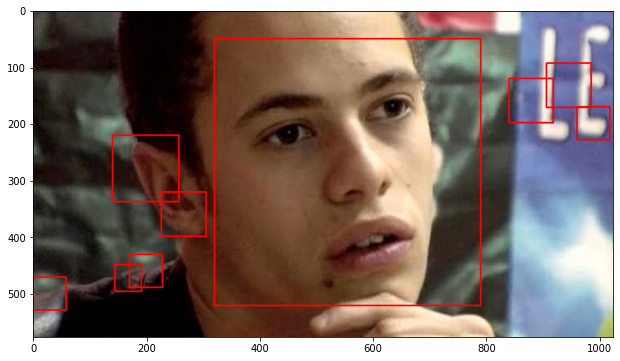

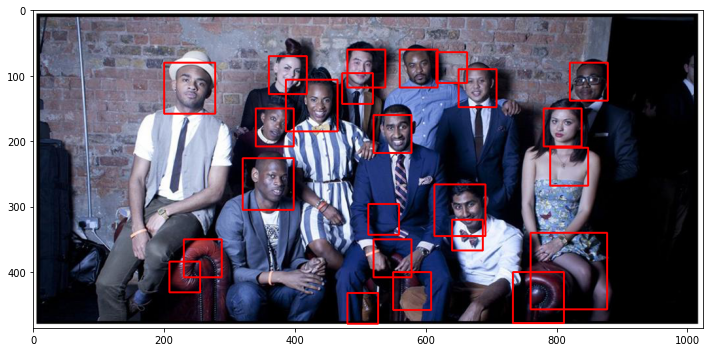

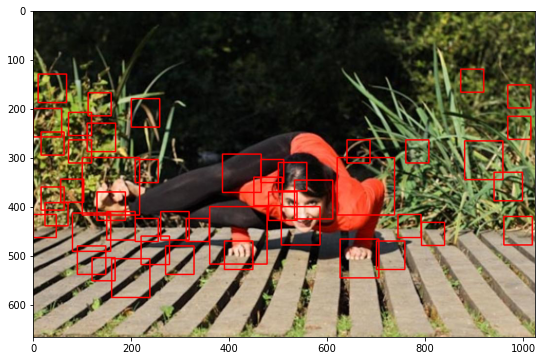

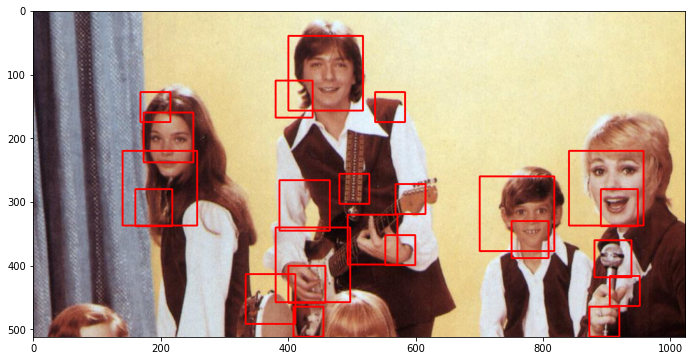

In [21]:
model_binary_conv.load_state_dict(torch.load('model.ckpt'))
full_conv_detector = FullyConvolutionalDetector(model_binary_conv,threshold=0.99)
images, boxes = read_images("/content/full_images", "/content/full_boxes")

N=len(images)

for i in range(N):

  all_face_coordinates, all_face_probabilities = full_conv_detector.detect_multi_scale(images[i])
  draw_boxes_with_gt(images[i], all_face_coordinates, gt_boxes=None)

###Threshold=0.9995
*   True positives: 18
*   False postives: 20

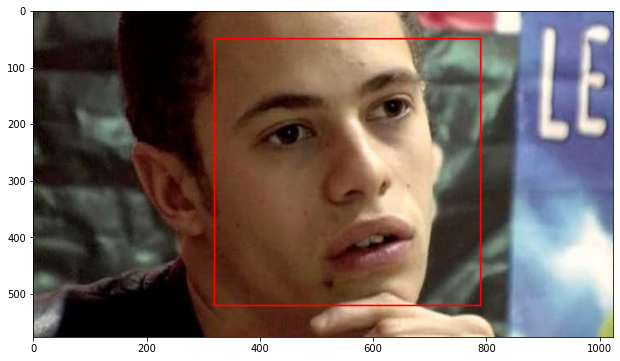

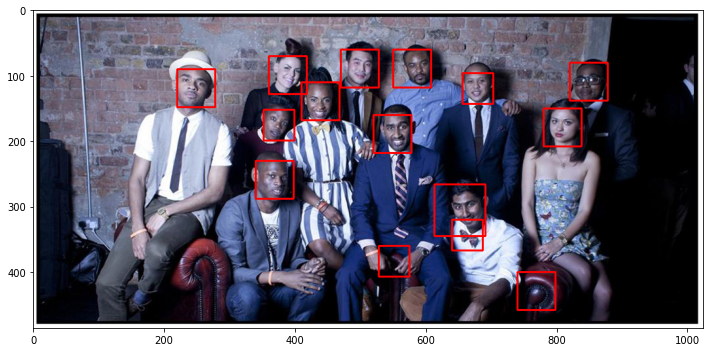

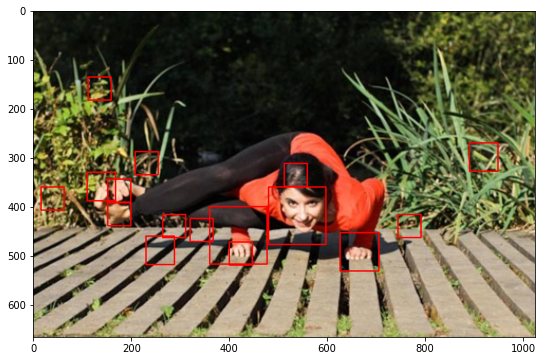

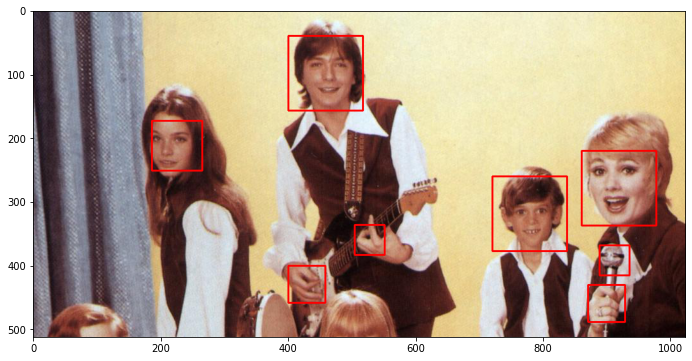

In [22]:
model_binary_conv.load_state_dict(torch.load('model.ckpt'))
full_conv_detector = FullyConvolutionalDetector(model_binary_conv,threshold=0.9995)
images, boxes = read_images("/content/full_images", "/content/full_boxes")

N=len(images)

for i in range(N):

  all_face_coordinates, all_face_probabilities = full_conv_detector.detect_multi_scale(images[i])
  draw_boxes_with_gt(images[i], all_face_coordinates, gt_boxes=None)

###Threshold=0.9998 (**selected threshold**) and nms = **True**
*   True positives: 18
*   False postives: 7

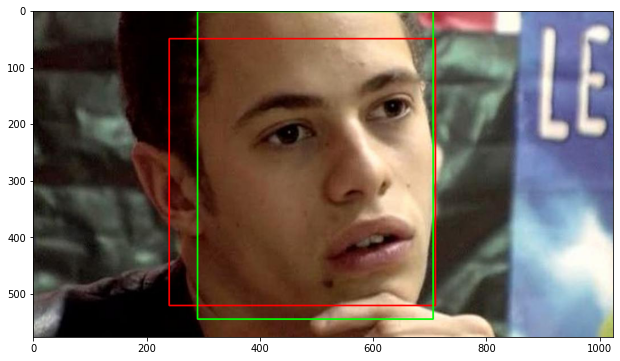

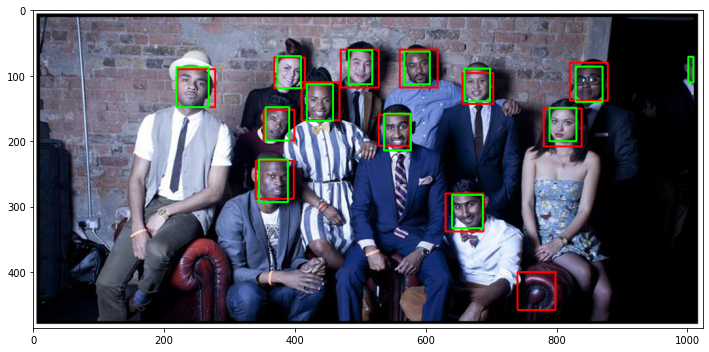

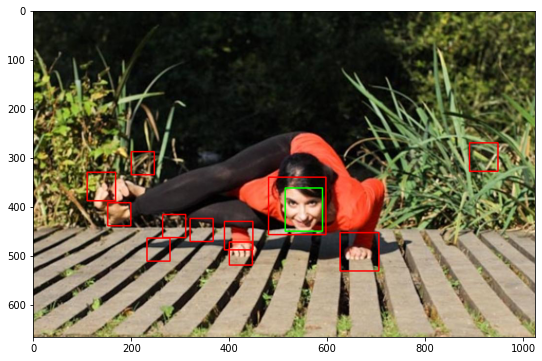

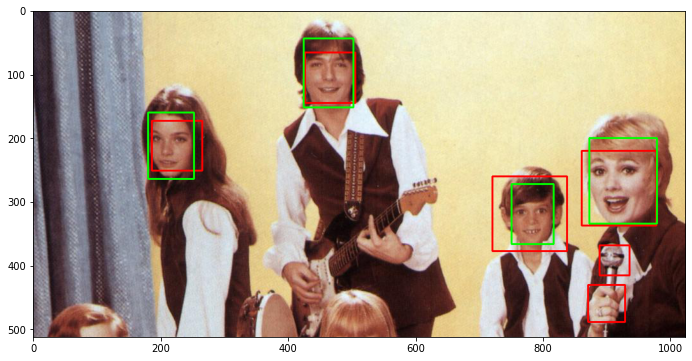

In [83]:
model_binary_conv.load_state_dict(torch.load('model.ckpt'))
full_conv_detector = FullyConvolutionalDetector(model_binary_conv,threshold=0.9998)
images, boxes = read_images("/content/full_images", "/content/full_boxes")

N=len(images)

for i in range(N):

  all_face_coordinates, all_face_probabilities = full_conv_detector.detect_multi_scale(images[i])
  draw_boxes_with_gt(images[i], all_face_coordinates, gt_boxes=boxes[i])

###threshold = 0.9998 (**selected threshold**) and nms = **False**


*   True positives: 18
*   False postives: 7

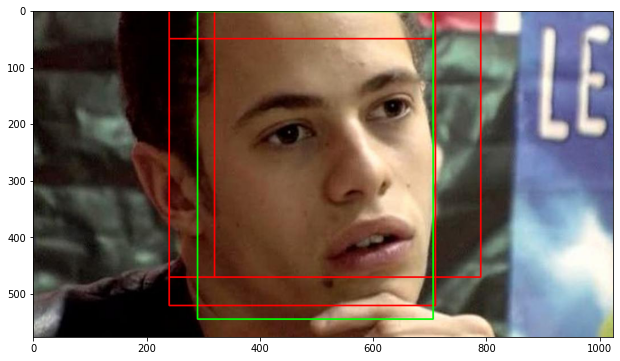

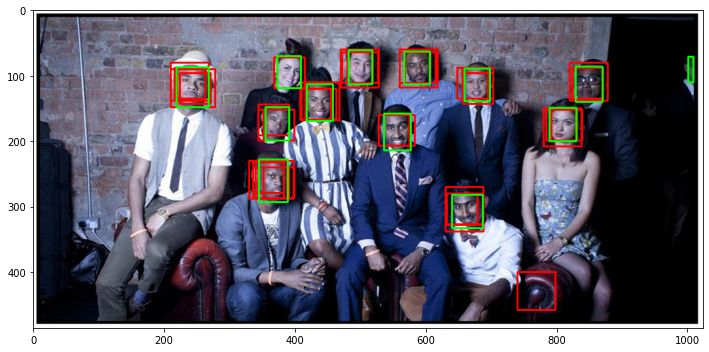

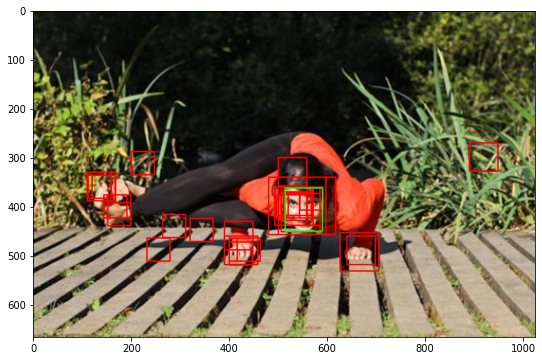

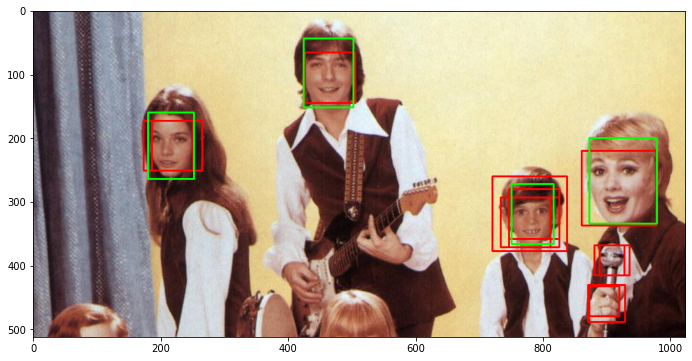

In [82]:
model_binary_conv.load_state_dict(torch.load('model.ckpt'))
full_conv_detector = FullyConvolutionalDetector(model_binary_conv,threshold=0.9998)
images, boxes = read_images("/content/full_images", "/content/full_boxes")

N=len(images)

for i in range(N):

  all_face_coordinates, all_face_probabilities = full_conv_detector.detect_multi_scale(images[i],nms_bool=False)
  draw_boxes_with_gt(images[i], all_face_coordinates, gt_boxes=boxes[i])

For threshold = 0.9998


*   True positives: 17 (One face is not detected)
*   False postives: 14

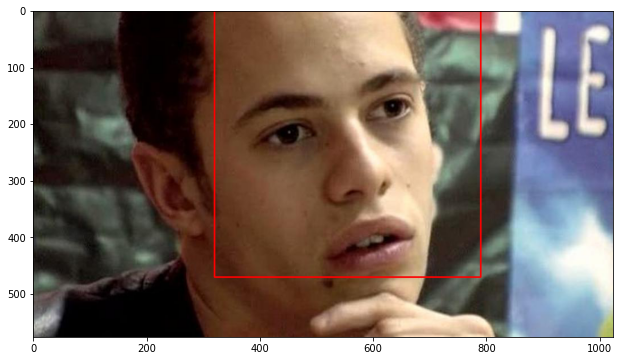

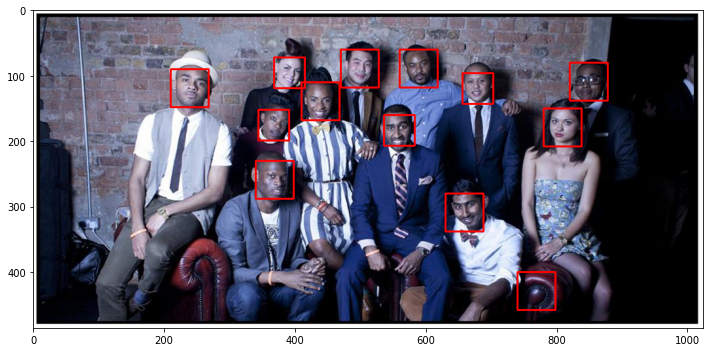

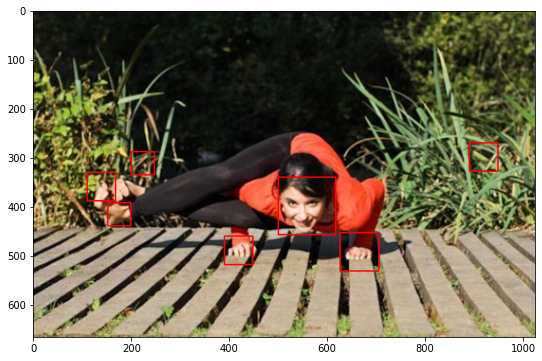

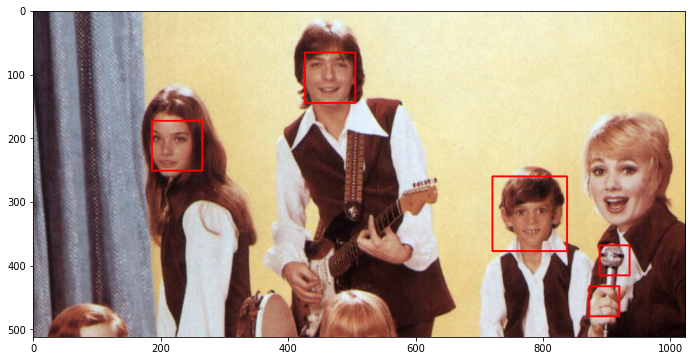

In [80]:
model_binary_conv.load_state_dict(torch.load('model.ckpt'))
full_conv_detector = FullyConvolutionalDetector(model_binary_conv,threshold=0.9999)
images, boxes = read_images("/content/full_images", "/content/full_boxes")

N=len(images)

for i in range(N):

  all_face_coordinates, all_face_probabilities = full_conv_detector.detect_multi_scale(images[i])
  draw_boxes_with_gt(images[i], all_face_coordinates, gt_boxes=None)

# 3. Improve your model
Propose different improvements and train new models (follow instructions from the pdf)

In this task, I have tested 5 different configurations. Each configuration uses the best parameters from the previous configuration and at the end of each configuration, the trained model is saved in the (model_instance_list and model_file_list) along with their best validation lost in best_val_list. After training all the configurations, we will choose the best one (based on its validation loss) and perform the face detection task on bigger images

In [26]:
model_instance_list=[]
model_file_list=[]
best_val_loss=[]

##Configuration 1
changes:


1.   Larger Batch size: [32,64,128,256]
2.   Larger learning rate: [3e-4,3e-4,3e-3,3e-3]
3.   Scheduling: step_size=5, gamma=0.1



In [27]:
training_curves_conf1 = {}

In [28]:
def train_scheduler(model, train_dataloader, val_dataloader, optimizer, n_epochs, loss_fn, scheduler=None):
    # We will monitor loss functions as the training progresses
    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []
    learning_rates = []

    for epoch in range(n_epochs):
        model.train()
        train_loss, train_accuracy = train(model, train_dataloader, optimizer, loss_fn)
        model.eval()
        val_loss, val_accuracy = test(model, val_dataloader, loss_fn)
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        train_accuracies.append(train_accuracy)
        val_accuracies.append(val_accuracy)
        
        learning_rates.append(optimizer.param_groups[0]['lr'])
        
        if scheduler:
            scheduler.step() 
        print('Epoch {}/{}: train_loss: {:.4f}, train_accuracy: {:.4f}, val_loss: {:.4f}, val_accuracy: {:.4f}'.format(epoch+1, n_epochs,
                                                                                                      train_losses[-1],
                                                                                                      train_accuracies[-1],
                                                                                                      val_losses[-1],
                                                                                                      val_accuracies[-1]))
    return train_losses, train_accuracies, val_losses, val_accuracies, learning_rates

In [29]:
b_arr = [32,64,128,256]
lr_arr = [3e-4,3e-4,3e-3,3e-3]


for b,lr in zip(b_arr,lr_arr):

  model_binary_conv_conf1 = BinaryConvModel()
  model_binary_conv_conf1 = model_binary_conv_conf1.to(device)  

  train_dataloader_conf1, val_dataloader_conf1 = get_dataloaders(train_dataset, val_dataset, batch_size=b)
  optimizer_conf1 = torch.optim.Adam(model_binary_conv_conf1.parameters(), lr=lr)
  
  n_epochs = 10
  loss_fn_conf1 = nn.CrossEntropyLoss()
  scheduler = torch.optim.lr_scheduler.StepLR(optimizer=optimizer_conf1, step_size=5, gamma=0.1) 
  Start = time.time()
  
  training_curves_conf1[b] = train_scheduler(model_binary_conv_conf1, train_dataloader_conf1, val_dataloader_conf1, optimizer_conf1, n_epochs, loss_fn_conf1, scheduler=scheduler)
  End = time.time()
  print("run time is={:f}".format(End-Start))


Epoch 1/10: train_loss: 0.2231, train_accuracy: 91.0578, val_loss: 0.1673, val_accuracy: 93.8300
Epoch 2/10: train_loss: 0.1530, train_accuracy: 94.2008, val_loss: 0.1401, val_accuracy: 94.7700
Epoch 3/10: train_loss: 0.1328, train_accuracy: 95.0101, val_loss: 0.1394, val_accuracy: 94.8700
Epoch 4/10: train_loss: 0.1193, train_accuracy: 95.5686, val_loss: 0.1240, val_accuracy: 95.3600
Epoch 5/10: train_loss: 0.1079, train_accuracy: 96.0578, val_loss: 0.1307, val_accuracy: 95.2500
Epoch 6/10: train_loss: 0.0781, train_accuracy: 97.1010, val_loss: 0.1078, val_accuracy: 96.0700
Epoch 7/10: train_loss: 0.0706, train_accuracy: 97.3618, val_loss: 0.1086, val_accuracy: 96.0600
Epoch 8/10: train_loss: 0.0667, train_accuracy: 97.5476, val_loss: 0.1102, val_accuracy: 96.0700
Epoch 9/10: train_loss: 0.0630, train_accuracy: 97.6841, val_loss: 0.1102, val_accuracy: 96.0900
Epoch 10/10: train_loss: 0.0598, train_accuracy: 97.8061, val_loss: 0.1112, val_accuracy: 96.2700
run time is=174.191484
Epoch 

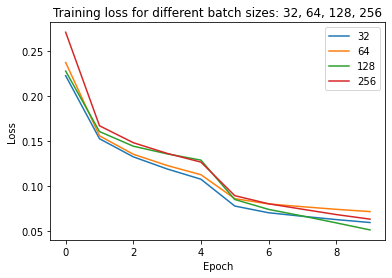

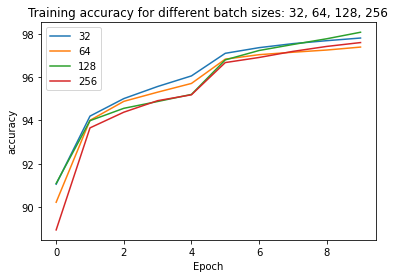

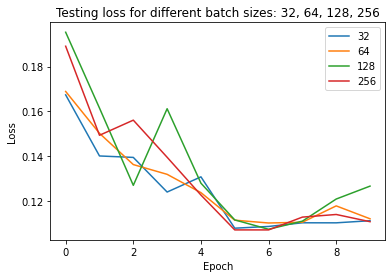

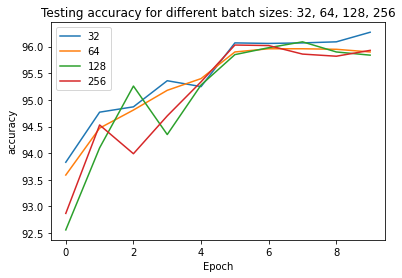

In [30]:
keys=[]

#Train plots
for k, v in training_curves_conf1.items():
    plt.plot(np.arange(len(v[0])), v[0])
    keys.append(k)
plt.title('Training loss for different batch sizes: 32, 64, 128, 256')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(keys)
plt.show()

for k, v in training_curves_conf1.items():
    plt.plot(np.arange(len(v[1])), v[1])
plt.title('Training accuracy for different batch sizes: 32, 64, 128, 256')
plt.xlabel('Epoch')
plt.ylabel('accuracy')
plt.legend(keys)
plt.show()

#Test plots
for k, v in training_curves_conf1.items():
    plt.plot(np.arange(len(v[2])), v[2])
    keys.append(k)
plt.title('Testing loss for different batch sizes: 32, 64, 128, 256')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(keys)
plt.show()

for k, v in training_curves_conf1.items():
    plt.plot(np.arange(len(v[3])), v[3])
plt.title('Testing accuracy for different batch sizes: 32, 64, 128, 256')
plt.xlabel('Epoch')
plt.ylabel('accuracy')
plt.legend(keys)
plt.show()


In [31]:
torch.save(model_binary_conv_conf1.state_dict(), 'model_tmp_conf1.ckpt')
torch.save(model_binary_conv_conf1.state_dict(), 'model_conf1.ckpt')
min_val_loss_conf1 = np.inf
best_batch_size = 256
for k, v in training_curves_conf1.items():

  if( v[2][-1] < min_val_loss_conf1):
    min_val_loss_conf1 = v[2][-1]
    best_batch_size = k
print("best batch size is {:f}".format(best_batch_size))    
if best_batch_size in [32,64]:
  best_learning_rate=3e-4
else:
  best_learning_rate=3e-3

print("best learning rate is {:f}".format(best_learning_rate))

model_instance_list.append(model_binary_conv_conf1)
model_file_list.append('model_conf1.ckpt')
best_val_loss.append(min_val_loss_conf1)

best batch size is 256.000000
best learning rate is 0.003000


These best batch size and learning rate are used in configuration 2,3,4, and 5

##Configuratiom 2
changes:




I have chosen to keep the overlapping max pooling layers because in AlexNet it is shown that they help reducing the error
1.   Increased filter size
3.   Normalization layers



In [34]:
class BinaryConvModel_conf2(nn.Module):
    
    def __init__(self):
          super(BinaryConvModel_conf2, self).__init__()
          self.conv_layers = nn.Sequential(
              # input size: 3x48x48
              nn.Conv2d(in_channels=3, out_channels=32, kernel_size=7, stride=1, padding=0),
              # output: 32x42x42 
              nn.MaxPool2d(kernel_size=3, stride=2, ceil_mode=True),
              # output: 32x21x21
              nn.BatchNorm2d(32),
              nn.LeakyReLU(0.2),
              # input: 32x21x21
              nn.Conv2d(in_channels=32, out_channels=64, kernel_size=5, stride=1, padding=0),
              # output: 64x17x17
              nn.MaxPool2d(kernel_size=3, stride=2, ceil_mode=True),
              # output: 64x8x8
              nn.BatchNorm2d(64),
              nn.LeakyReLU(0.2),
              # intput: 64x8x8
              nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3, stride=1, padding=0),
              # output: 64x6x6
              nn.MaxPool2d(kernel_size=2, stride=2),
              # output: 64x3x3
              nn.BatchNorm2d(64),
              nn.LeakyReLU(0.2),
              # intput: 64x3x3
              nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, stride=1, padding=0),
              # output: 128x1x1
              nn.BatchNorm2d(128),
              nn.LeakyReLU(0.2),
              # intput: 128x1x1
              nn.Conv2d(in_channels=128, out_channels=2, kernel_size=1, stride=1, padding=0)
              # output: 2x1x1
              
          )
          
    def forward(self, input):

        output = self.conv_layers(input)
        
        return output

Epoch 1/10: train_loss: 0.2533, train_accuracy: 89.6922, val_loss: 0.2891, val_accuracy: 88.5600
Epoch 2/10: train_loss: 0.1733, train_accuracy: 93.2483, val_loss: 0.1643, val_accuracy: 93.8300
Epoch 3/10: train_loss: 0.1539, train_accuracy: 94.0967, val_loss: 0.2293, val_accuracy: 91.5500
Epoch 4/10: train_loss: 0.1383, train_accuracy: 94.7403, val_loss: 0.1684, val_accuracy: 93.3400
Epoch 5/10: train_loss: 0.1293, train_accuracy: 95.0817, val_loss: 0.1287, val_accuracy: 95.0800
Epoch 6/10: train_loss: 0.1224, train_accuracy: 95.3526, val_loss: 0.1278, val_accuracy: 94.9100
Epoch 7/10: train_loss: 0.1150, train_accuracy: 95.6481, val_loss: 0.1877, val_accuracy: 93.0900
Epoch 8/10: train_loss: 0.1091, train_accuracy: 95.8887, val_loss: 0.1262, val_accuracy: 95.0700
Epoch 9/10: train_loss: 0.1033, train_accuracy: 96.0768, val_loss: 0.1818, val_accuracy: 93.5800
Epoch 10/10: train_loss: 0.0991, train_accuracy: 96.2223, val_loss: 0.1309, val_accuracy: 95.1500
run time is=89.488502


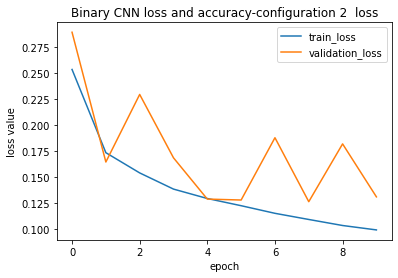

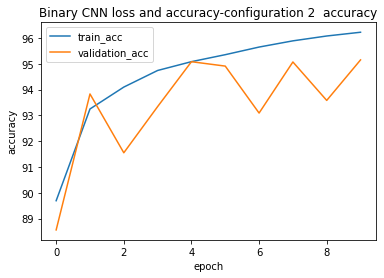

In [35]:
model_binary_conv_conf2 = BinaryConvModel_conf2()
model_binary_conv_conf2 = model_binary_conv_conf2.to(device)

batch_size = best_batch_size
train_dataloader_conf2, val_dataloader_conf2 = get_dataloaders(train_dataset, val_dataset, batch_size=batch_size)

learning_rate = best_learning_rate
optimizer_conf2 = torch.optim.Adam(model_binary_conv_conf2.parameters(), lr=learning_rate)
n_epochs = 10
loss_fn_conf2 = nn.CrossEntropyLoss()

Start = time.time()
train_losses_conf2, train_accuracies_conf2, val_losses_conf2, val_accuracies_conf2 = fit(train_dataloader_conf2, val_dataloader_conf2, model_binary_conv_conf2, optimizer_conf2, loss_fn_conf2, n_epochs)
End = time.time()

print("run time is={:f}".format(End-Start))

plot_fnc(train_losses_conf2, val_losses_conf2, train_accuracies_conf2, val_accuracies_conf2,"Binary CNN loss and accuracy-configuration 2 ","train","validation")

As the model's capacity has decreased compared to task1, we tune the initial model in the following configurations

In [36]:
torch.save(model_binary_conv_conf2.state_dict(), 'model_tmp_conf2.ckpt')
torch.save(model_binary_conv_conf2.state_dict(), 'model_conf2.ckpt')

model_instance_list.append(model_binary_conv_conf2)
model_file_list.append('model_conf2.ckpt')
best_val_loss.append(val_losses_conf2[-1])

##Configuration 3
changes:


1.   early stopping: if no improvement after 5 epochs, stop training
2.   Dropouts: dropout_p = [0, 0.1, 0.2]

3.   L2 regularization / weight decay: alpha = [0, 0.001, 0.01]

4. This config uses the best batch size and the best learning rate from the first config and the model (with increased capacity from the second config)

I also tested data_augmentation but given it did not improve the result and also used a lot of RAM, its results are not included here.

In [48]:
#used when selecting best weight decay value
training_curves_wd = {}
#used when selecting best dropout probability value
training_curves_dp = {}

training_curves_conf3 = {}

Early stopping

In [49]:
from copy import deepcopy

def train_early_stopping(model, train_dataloader, val_dataloader, optimizer, n_epochs, loss_fn):
    
    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []

    ### EARLY STOPPING INITIALIZATION
    best_val_loss = np.inf
    best_model = None
    patience = 5 
    counter = 0
    ###

    for epoch in range(n_epochs):
        model.train()
        train_loss, train_accuracy = train(model, train_dataloader, optimizer, loss_fn)
        model.eval()
        val_loss, val_accuracy = test(model, val_dataloader, loss_fn)
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        train_accuracies.append(train_accuracy)
        val_accuracies.append(val_accuracy)
        print('Epoch {}/{}: train_loss: {:.4f}, train_accuracy: {:.4f}, val_loss: {:.4f}, val_accuracy: {:.4f}'.format(epoch+1, n_epochs,
                                                                                                      train_losses[-1],
                                                                                                      train_accuracies[-1],
                                                                                                      val_losses[-1],
                                                                                                      val_accuracies[-1]))
    
        ### EARLY STOPPING CODE
        if val_loss < best_val_loss: # 
            best_val_loss = val_loss
            best_model = deepcopy(model)
            counter = 0
        else: 
            counter += 1
        if counter == patience: # If no improvement for some number of epochs, stop training
            print('No improvement for {} epochs; training stopped.'.format(patience))
            break
    # Copy best model parameters to model
    for param1, param2 in zip(model.parameters(), best_model.parameters()):
        param1.data = param2.data
    ###
    return train_losses, train_accuracies, val_losses,  val_accuracies

Dropouts

In [50]:
class BinaryConvModel_conf3(nn.Module):
    
    def __init__(self,dropout_p = 0.5):
          super(BinaryConvModel_conf3, self).__init__()
          self.conv_layers = nn.Sequential(
              # input size: 3x48x48
              nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, stride=1, padding=0),
              # output: 32x46x46 (because kernel_size=3 and no padding)
              nn.MaxPool2d(kernel_size=3, stride=2, ceil_mode=True),
              # output: 32x23x23
              nn.BatchNorm2d(32),
              nn.LeakyReLU(0.2),
              nn.Dropout(dropout_p),
              # input: 32x23x23
              nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=0),
              # output: 64x21x21
              nn.MaxPool2d(kernel_size=3, stride=2),
              # output: 64x10x10
              nn.BatchNorm2d(64),
              nn.LeakyReLU(0.2),
              nn.Dropout(dropout_p),
              # intput: 64x10x10
              nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3, stride=1, padding=0),
              # output: 64x8x8
              nn.MaxPool2d(kernel_size=2, stride=2),
              # output: 64x4x4
              nn.BatchNorm2d(64),
              nn.LeakyReLU(0.2),
              nn.Dropout(dropout_p),
              # intput: 64x4x4
              nn.Conv2d(in_channels=64, out_channels=128, kernel_size=2, stride=1, padding=0),
              # output: 128x3x3
              nn.BatchNorm2d(128),
              nn.LeakyReLU(0.2),
              nn.Dropout(dropout_p),
              # intput: 128x3x3
              nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, stride=1, padding=0),
              # output: 256x1x1
              nn.BatchNorm2d(256),
              nn.LeakyReLU(0.2),
              nn.Dropout(dropout_p),
              # intput: 256x1x1
              nn.Conv2d(in_channels=256, out_channels=2, kernel_size=1, stride=1, padding=0),
              # output: 2x1x1
          )
          
      
    def forward(self, input):
        output = self.conv_layers(input)
        return output

Weight decay

In [51]:
learning_rate = best_learning_rate

dropout_p =  0

model_binary_conv_conf3 = BinaryConvModel_conf3(dropout_p = dropout_p)
model_binary_conv_conf3 = model_binary_conv_conf3.to(device)

### choosing weight decay value

In [52]:
n_epochs = 50
loss_fn_conf3 = nn.CrossEntropyLoss()

alpha_arr = [0, 0.001, 0.01]

for a in alpha_arr:

  print("weight decay is {:f}".format(a))
  optimizer_conf3 = torch.optim.Adam(model_binary_conv_conf3.parameters(), lr=learning_rate, weight_decay=a)
  Start = time.time()
  #train_losses_conf4, train_accuracies_conf4, val_losses_conf4, val_accuracies_conf4
  training_curves_wd[a] = train_early_stopping(model_binary_conv_conf3, train_dataloader_conf2, val_dataloader_conf2, optimizer_conf3, n_epochs, loss_fn_conf3)
  End = time.time()
  print("run time is={:f}".format(End-Start))

weight decay is 0.000000
Epoch 1/50: train_loss: 0.2315, train_accuracy: 90.9425, val_loss: 0.1725, val_accuracy: 93.1000
Epoch 2/50: train_loss: 0.1536, train_accuracy: 94.2053, val_loss: 0.1490, val_accuracy: 94.3400
Epoch 3/50: train_loss: 0.1349, train_accuracy: 94.9362, val_loss: 0.1366, val_accuracy: 94.6300
Epoch 4/50: train_loss: 0.1228, train_accuracy: 95.4253, val_loss: 0.1320, val_accuracy: 94.9200
Epoch 5/50: train_loss: 0.1138, train_accuracy: 95.7309, val_loss: 0.1396, val_accuracy: 94.5700
Epoch 6/50: train_loss: 0.1049, train_accuracy: 95.9928, val_loss: 0.1167, val_accuracy: 95.6000
Epoch 7/50: train_loss: 0.0991, train_accuracy: 96.2783, val_loss: 0.1296, val_accuracy: 95.4200
Epoch 8/50: train_loss: 0.0938, train_accuracy: 96.4775, val_loss: 0.1150, val_accuracy: 95.6500
Epoch 9/50: train_loss: 0.0849, train_accuracy: 96.8010, val_loss: 0.1578, val_accuracy: 94.1800
Epoch 10/50: train_loss: 0.0803, train_accuracy: 96.9129, val_loss: 0.1136, val_accuracy: 95.9300
Epoc

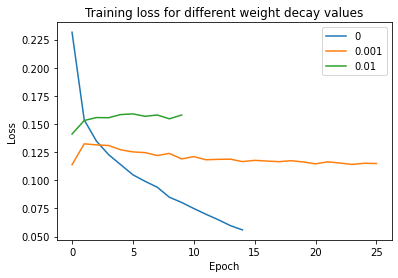

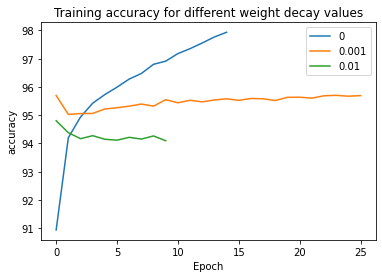

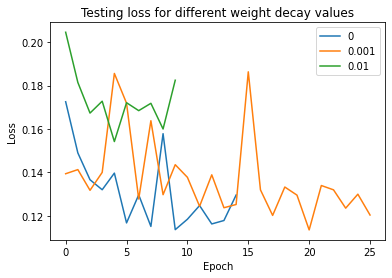

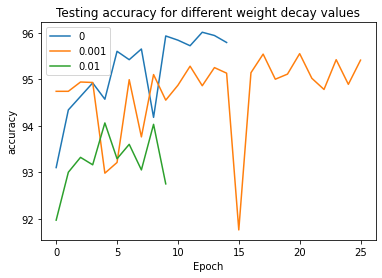

In [53]:
keys=[]

#Train plots
for k, v in training_curves_wd.items():
    plt.plot(np.arange(len(v[0])), v[0])
    keys.append(k)
plt.title('Training loss for different weight decay values')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(keys);
plt.show()

for k, v in training_curves_wd.items():
    plt.plot(np.arange(len(v[1])), v[1])
plt.title('Training accuracy for different weight decay values')
plt.xlabel('Epoch')
plt.ylabel('accuracy')
plt.legend(keys);
plt.show()

#Test plots
for k, v in training_curves_wd.items():
    plt.plot(np.arange(len(v[2])), v[2])
    keys.append(k)
plt.title('Testing loss for different weight decay values')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(keys);
plt.show()

for k, v in training_curves_wd.items():
    plt.plot(np.arange(len(v[3])), v[3])
plt.title('Testing accuracy for different weight decay values')
plt.xlabel('Epoch')
plt.ylabel('accuracy')
plt.legend(keys);
plt.show()

In [54]:
min_val_loss_wd = np.inf
best_weight_decay = 0
for k, v in training_curves_wd.items():
  if(v[2][-1] < min_val_loss_wd):
    min_val_loss_wd = v[2][-1]
    best_weight_decay = k
print("best_weight_decay is {:f}".format(best_weight_decay))

best_weight_decay is 0.001000


###chossing droupout probability


In [55]:
n_epochs = 50
loss_fn_conf3 = nn.CrossEntropyLoss()

alpha = best_weight_decay 
learning_rate = best_learning_rate

droupout_p_arr=[0, 0.1, 0.2]

for p in droupout_p_arr:

  print("dropout probability is {:f}".format(p))
  model_binary_conv_conf3 = BinaryConvModel_conf3(dropout_p = p)
  model_binary_conv_conf3 = model_binary_conv_conf3.to(device)

  optimizer_conf3 = torch.optim.Adam(model_binary_conv_conf3.parameters(), lr=learning_rate, weight_decay=alpha)
  
  Start = time.time()
  
  training_curves_dp[p] = train_early_stopping(model_binary_conv_conf3, train_dataloader_conf2, val_dataloader_conf2, optimizer_conf3, n_epochs, loss_fn_conf3)
  End = time.time()
  print("run time is={:f}".format(End-Start))

dropout probability is 0.000000
Epoch 1/50: train_loss: 0.2600, train_accuracy: 89.5948, val_loss: 0.2222, val_accuracy: 90.4100
Epoch 2/50: train_loss: 0.1743, train_accuracy: 93.3154, val_loss: 0.1752, val_accuracy: 93.0600
Epoch 3/50: train_loss: 0.1608, train_accuracy: 93.8796, val_loss: 0.1486, val_accuracy: 94.3700
Epoch 4/50: train_loss: 0.1516, train_accuracy: 94.2691, val_loss: 0.1631, val_accuracy: 93.4000
Epoch 5/50: train_loss: 0.1454, train_accuracy: 94.5276, val_loss: 0.1382, val_accuracy: 94.7600
Epoch 6/50: train_loss: 0.1427, train_accuracy: 94.5321, val_loss: 0.1547, val_accuracy: 94.0700
Epoch 7/50: train_loss: 0.1369, train_accuracy: 94.7761, val_loss: 0.1404, val_accuracy: 94.6800
Epoch 8/50: train_loss: 0.1345, train_accuracy: 94.9239, val_loss: 0.1592, val_accuracy: 93.7600
Epoch 9/50: train_loss: 0.1331, train_accuracy: 94.9586, val_loss: 0.1665, val_accuracy: 93.2300
Epoch 10/50: train_loss: 0.1290, train_accuracy: 95.1623, val_loss: 0.1291, val_accuracy: 95.08

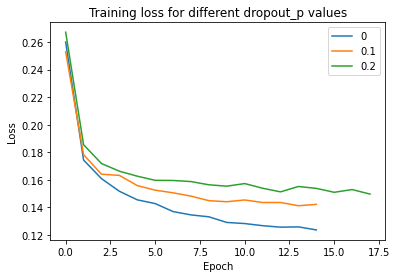

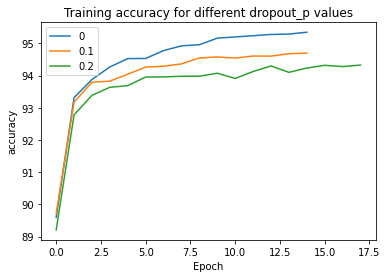

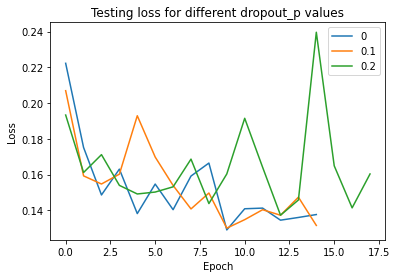

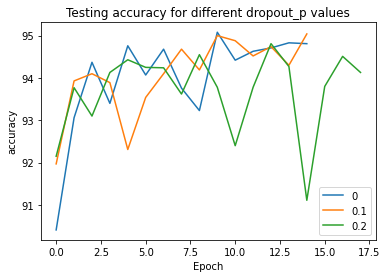

In [56]:
keys=[]

#Train plots
for k, v in training_curves_dp.items():
    plt.plot(np.arange(len(v[0])), v[0])
    keys.append(k)
plt.title('Training loss for different dropout_p values')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(keys);
plt.show()

for k, v in training_curves_dp.items():
    plt.plot(np.arange(len(v[1])), v[1])
plt.title('Training accuracy for different dropout_p values')
plt.xlabel('Epoch')
plt.ylabel('accuracy')
plt.legend(keys);
plt.show()

#Test plots
for k, v in training_curves_dp.items():
    plt.plot(np.arange(len(v[2])), v[2])
    keys.append(k)
plt.title('Testing loss for different dropout_p values')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(keys);
plt.show()

for k, v in training_curves_dp.items():
    plt.plot(np.arange(len(v[3])), v[3])
plt.title('Testing accuracy for different dropout_p values')
plt.xlabel('Epoch')
plt.ylabel('accuracy')
plt.legend(keys);
plt.show()

In [57]:
min_val_loss_dp = np.inf
best_dropout_p = 0
for k, v in training_curves_dp.items():
  if(v[2][-1] < min_val_loss_dp):
    min_val_loss_dp = v[2][-1]
    best_dropout_p = k
print("best_dropout_p is {:f}".format(best_dropout_p))

best_dropout_p is 0.100000


##Configuration 4
changes:


1.   Using different optimizer

>*  SGD with Nesterov Momentum
>*  Adagrad
>*  RMSprop
>*  Adam






In [64]:
training_curves_conf4 = {}

In [65]:
learning_rate = best_learning_rate

#==========================================================================SGD with Nesterov Momentum========================================================================================
model_binary_conv_sgd_nm = BinaryConvModel_conf3(dropout_p = best_dropout_p)
model_binary_conv_sgd_nm = model_binary_conv_sgd_nm.to(device)

optimizer_sgd_nm = torch.optim.SGD(model_binary_conv_sgd_nm.parameters(), lr=learning_rate, momentum=0.9, nesterov=True)
#==========================================================================Adagrad========================================================================================
model_binary_conv_Adagrad = BinaryConvModel_conf3(dropout_p = best_dropout_p)
model_binary_conv_Adagrad = model_binary_conv_Adagrad.to(device)

optimizer_Adagrad = torch.optim.Adagrad(model_binary_conv_Adagrad.parameters(), lr=learning_rate)
#==========================================================================RMSprop========================================================================================
model_binary_conv_RMSprop = BinaryConvModel_conf3(dropout_p = best_dropout_p)
model_binary_conv_RMSprop = model_binary_conv_RMSprop.to(device)

optimizer_RMSprop = torch.optim.RMSprop(model_binary_conv_RMSprop.parameters(), lr=learning_rate)
#==========================================================================Adam========================================================================================
model_binary_conv_adam = BinaryConvModel_conf3(dropout_p = best_dropout_p)
model_binary_conv_adam = model_binary_conv_adam.to(device)

optimizer_adam = torch.optim.Adam(model_binary_conv_adam.parameters(), lr=learning_rate)

n_epochs = 15
loss_fn = nn.CrossEntropyLoss()
 

In [66]:
#==========================================================================SGD with Nesterov Momentum========================================================================================
print("#==========================================================================SGD with Nesterov Momentum========================================================================================")
training_curves_conf4['SGD with Nesterov Momentum'] = train_early_stopping( model_binary_conv_sgd_nm, train_dataloader_conf2, val_dataloader_conf2, optimizer_sgd_nm, n_epochs, loss_fn)


#==========================================================================SGD with Nesterov Momentum========================================================================================
Epoch 1/15: train_loss: 0.2608, train_accuracy: 89.2445, val_loss: 0.2212, val_accuracy: 91.2700
Epoch 2/15: train_loss: 0.1869, train_accuracy: 92.7356, val_loss: 0.1930, val_accuracy: 92.6300
Epoch 3/15: train_loss: 0.1679, train_accuracy: 93.4811, val_loss: 0.1686, val_accuracy: 93.4700
Epoch 4/15: train_loss: 0.1567, train_accuracy: 94.0687, val_loss: 0.1542, val_accuracy: 94.1100
Epoch 5/15: train_loss: 0.1493, train_accuracy: 94.2780, val_loss: 0.1541, val_accuracy: 93.8800
Epoch 6/15: train_loss: 0.1410, train_accuracy: 94.6530, val_loss: 0.1613, val_accuracy: 93.7500
Epoch 7/15: train_loss: 0.1367, train_accuracy: 94.8522, val_loss: 0.1443, val_accuracy: 94.2000
Epoch 8/15: train_loss: 0.1309, train_accuracy: 94.9675, val_loss: 0.1333, val_accuracy: 94.9300
Epoch 9/15: train_loss: 0.1277, tr

In [84]:
#==========================================================================Adagrad========================================================================================
print("#==========================================================================Adagrad========================================================================================")
training_curves_conf4['Adagrad'] = train_early_stopping(model_binary_conv_Adagrad, train_dataloader_conf2, val_dataloader_conf2,  optimizer_Adagrad, n_epochs, loss_fn)


#==========================================================================Adagrad========================================================================================
Epoch 1/15: train_loss: 0.2384, train_accuracy: 90.3772, val_loss: 0.1810, val_accuracy: 92.6600
Epoch 2/15: train_loss: 0.1692, train_accuracy: 93.4296, val_loss: 0.1640, val_accuracy: 93.6800
Epoch 3/15: train_loss: 0.1522, train_accuracy: 94.1627, val_loss: 0.1570, val_accuracy: 93.8700
Epoch 4/15: train_loss: 0.1446, train_accuracy: 94.4347, val_loss: 0.1491, val_accuracy: 94.1600
Epoch 5/15: train_loss: 0.1372, train_accuracy: 94.7784, val_loss: 0.1442, val_accuracy: 94.1100
Epoch 6/15: train_loss: 0.1310, train_accuracy: 95.0571, val_loss: 0.1453, val_accuracy: 94.1800
Epoch 7/15: train_loss: 0.1282, train_accuracy: 95.1052, val_loss: 0.1539, val_accuracy: 94.0400
Epoch 8/15: train_loss: 0.1234, train_accuracy: 95.3974, val_loss: 0.1382, val_accuracy: 94.5900
Epoch 9/15: train_loss: 0.1221, train_accuracy: 95.36

In [85]:
#==========================================================================RMSprop========================================================================================
print("#==========================================================================RMSprop========================================================================================")
training_curves_conf4['RMSprop'] = train_early_stopping(model_binary_conv_RMSprop, train_dataloader_conf2, val_dataloader_conf2, optimizer_RMSprop, n_epochs, loss_fn)

#==========================================================================RMSprop========================================================================================
Epoch 1/15: train_loss: 0.3016, train_accuracy: 87.5856, val_loss: 0.2609, val_accuracy: 89.2800
Epoch 2/15: train_loss: 0.1893, train_accuracy: 92.6696, val_loss: 0.1944, val_accuracy: 91.9500
Epoch 3/15: train_loss: 0.1616, train_accuracy: 93.9266, val_loss: 0.2008, val_accuracy: 92.5100
Epoch 4/15: train_loss: 0.1465, train_accuracy: 94.5097, val_loss: 0.1373, val_accuracy: 94.6700
Epoch 5/15: train_loss: 0.1364, train_accuracy: 94.8623, val_loss: 0.2767, val_accuracy: 90.5700
Epoch 6/15: train_loss: 0.1291, train_accuracy: 95.1131, val_loss: 0.1245, val_accuracy: 95.4100
Epoch 7/15: train_loss: 0.1204, train_accuracy: 95.4556, val_loss: 0.1189, val_accuracy: 95.3400
Epoch 8/15: train_loss: 0.1153, train_accuracy: 95.6391, val_loss: 0.1343, val_accuracy: 95.0700
Epoch 9/15: train_loss: 0.1112, train_accuracy: 95.80

In [86]:
#==========================================================================Adam========================================================================================
print("#==========================================================================Adam========================================================================================")
training_curves_conf4['Adam'] = train_early_stopping(model_binary_conv_adam, train_dataloader_conf2, val_dataloader_conf2, optimizer_adam, n_epochs, loss_fn)


#==========================================================================Adam========================================================================================
Epoch 1/15: train_loss: 0.2457, train_accuracy: 90.1657, val_loss: 0.1639, val_accuracy: 93.5500
Epoch 2/15: train_loss: 0.1623, train_accuracy: 93.8258, val_loss: 0.1408, val_accuracy: 94.5400
Epoch 3/15: train_loss: 0.1429, train_accuracy: 94.5758, val_loss: 0.1415, val_accuracy: 94.7600
Epoch 4/15: train_loss: 0.1322, train_accuracy: 94.9642, val_loss: 0.1319, val_accuracy: 95.1500
Epoch 5/15: train_loss: 0.1230, train_accuracy: 95.3974, val_loss: 0.1202, val_accuracy: 95.3700
Epoch 6/15: train_loss: 0.1181, train_accuracy: 95.5753, val_loss: 0.1167, val_accuracy: 95.6000
Epoch 7/15: train_loss: 0.1113, train_accuracy: 95.8585, val_loss: 0.1123, val_accuracy: 95.8200
Epoch 8/15: train_loss: 0.1067, train_accuracy: 96.0208, val_loss: 0.1227, val_accuracy: 95.5900
Epoch 9/15: train_loss: 0.1021, train_accuracy: 96.1921,

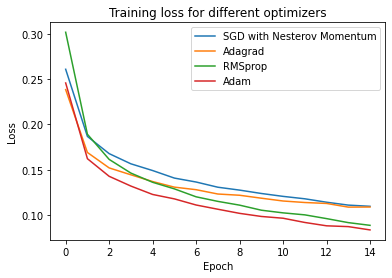

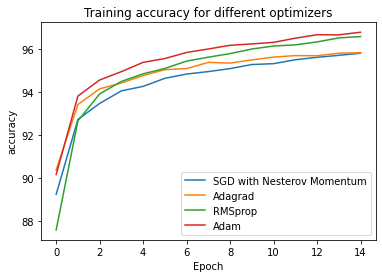

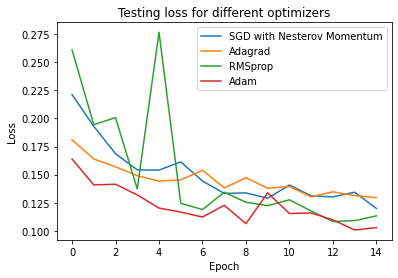

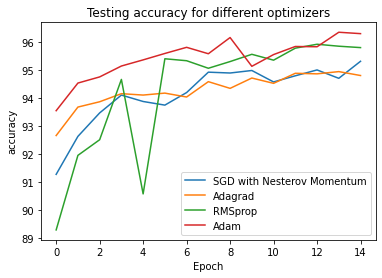

In [87]:
keys=[]

#Train plots
for k, v in training_curves_conf4.items():
    plt.plot(np.arange(len(v[0])), v[0])
    keys.append(k)
plt.title('Training loss for different optimizers')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(keys);
plt.show()

for k, v in training_curves_conf4.items():
    plt.plot(np.arange(len(v[1])), v[1])
plt.title('Training accuracy for different optimizers')
plt.xlabel('Epoch')
plt.ylabel('accuracy')
plt.legend(keys);
plt.show()

#Test plots
for k, v in training_curves_conf4.items():
    plt.plot(np.arange(len(v[2])), v[2])
    keys.append(k)
plt.title('Testing loss for different optimizers')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(keys);
plt.show()

for k, v in training_curves_conf4.items():
    plt.plot(np.arange(len(v[3])), v[3])
plt.title('Testing accuracy for different optimizers')
plt.xlabel('Epoch')
plt.ylabel('accuracy')
plt.legend(keys);
plt.show()

In [88]:
min_val_loss_conf4 = np.inf
best_optimizer = np.nan
for k, v in training_curves_conf4.items():
  if( v[2][-1] < min_val_loss_conf4 ):
    min_val_loss_conf4 = v[2][-1]
    best_optimizer = k

print("best optimizer is "+ best_optimizer)

if(best_optimizer == 'SGD with Nesterov Momentum'):

  torch.save(model_binary_conv_sgd_nm.state_dict(), 'model_tmp_conf4.ckpt')
  torch.save(model_binary_conv_sgd_nm.state_dict(), 'model_conf4.ckpt')
  model_instance_list.append(model_binary_conv_sgd_nm)

elif(best_optimizer == 'Adagrad'):

  torch.save(model_binary_conv_Adagrad.state_dict(), 'model_tmp_conf4.ckpt')
  torch.save(model_binary_conv_Adagrad.state_dict(), 'model_conf4.ckpt')
  model_instance_list.append(model_binary_conv_Adagrad)

elif(best_optimizer == 'RMSprop'):

  torch.save(model_binary_conv_RMSprop.state_dict(), 'model_tmp_conf4.ckpt')
  torch.save(model_binary_conv_RMSprop.state_dict(), 'model_conf4.ckpt')
  model_instance_list.append(model_binary_conv_RMSprop)

else:
  torch.save(model_binary_conv_adam.state_dict(), 'model_tmp_conf4.ckpt')
  torch.save(model_binary_conv_adam.state_dict(), 'model_conf4.ckpt')
  model_instance_list.append(model_binary_conv_adam)    

model_file_list.append('model_conf4.ckpt')
best_val_loss.append(min_val_loss_conf4)

best optimizer is Adam


##Configuration 5
In this configuration, I apply all the changes at one place


Changes include:

1. training paramters


>*   batch size: best batch size from config 1
>*   Larger learning rate : best learning rate from config 1
>*   Scheduling: step_size=5, gamma=0.1


2.  Network architecture: config 3

>*  Normalization layers
>*  Dropout layers

3.  Optimizer: best optimizer in config 4

3. Model regularization

>*   early stopping: if no improvement after 5 epochs, stop training
>*   Dropouts: best dropout_p from configuration 3
>*   L2 regularization / weight decay: best weight decay from config 3



train method

In [58]:
from copy import deepcopy

def train_conf5(model, train_dataloader, val_dataloader, optimizer, n_epochs, loss_fn, scheduler=None):
    
    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []

    ### EARLY STOPPING INITIALIZATION
    best_val_loss = np.inf
    best_model = None
    patience = 5 
    counter = 0
    ###

    for epoch in range(n_epochs):

        model.train()
        train_loss, train_accuracy = train(model, train_dataloader, optimizer, loss_fn)
        model.eval()
        val_loss, val_accuracy = test(model, val_dataloader, loss_fn)
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        train_accuracies.append(train_accuracy)
        val_accuracies.append(val_accuracy)
        
        if scheduler:
            scheduler.step() 
        
        print('Epoch {}/{}: train_loss: {:.4f}, train_accuracy: {:.4f}, val_loss: {:.4f}, val_accuracy: {:.4f}'.format(epoch+1, n_epochs,
                                                                                                      train_losses[-1],
                                                                                                      train_accuracies[-1],
                                                                                                      val_losses[-1],
                                                                                                      val_accuracies[-1]))
    
        ### EARLY STOPPING CODE
        if val_loss < best_val_loss: # 
            best_val_loss = val_loss
            best_model = deepcopy(model)
            counter = 0
        else: 
            counter += 1
        if counter == patience: # If no improvement for some number of epochs, stop training
            print('No improvement for {} epochs; training stopped.'.format(patience))
            break
    # Copy best model parameters to model
    for param1, param2 in zip(model.parameters(), best_model.parameters()):
        param1.data = param2.data
    ###
    return train_losses, train_accuracies, val_losses,  val_accuracies

Epoch 1/50: train_loss: 0.2528, train_accuracy: 89.8511, val_loss: 0.1727, val_accuracy: 93.2300
Epoch 2/50: train_loss: 0.1766, train_accuracy: 93.1263, val_loss: 0.1525, val_accuracy: 94.2100
Epoch 3/50: train_loss: 0.1657, train_accuracy: 93.6691, val_loss: 0.1599, val_accuracy: 93.8900
Epoch 4/50: train_loss: 0.1592, train_accuracy: 93.9255, val_loss: 0.1712, val_accuracy: 93.2700
Epoch 5/50: train_loss: 0.1578, train_accuracy: 93.9881, val_loss: 0.1709, val_accuracy: 93.0100
Epoch 6/50: train_loss: 0.1279, train_accuracy: 95.0929, val_loss: 0.1160, val_accuracy: 95.6900
Epoch 7/50: train_loss: 0.1190, train_accuracy: 95.4645, val_loss: 0.1167, val_accuracy: 95.5400
Epoch 8/50: train_loss: 0.1154, train_accuracy: 95.6414, val_loss: 0.1150, val_accuracy: 95.7300
Epoch 9/50: train_loss: 0.1122, train_accuracy: 95.7544, val_loss: 0.1067, val_accuracy: 95.9700
Epoch 10/50: train_loss: 0.1093, train_accuracy: 95.9290, val_loss: 0.1074, val_accuracy: 95.8200
Epoch 11/50: train_loss: 0.10

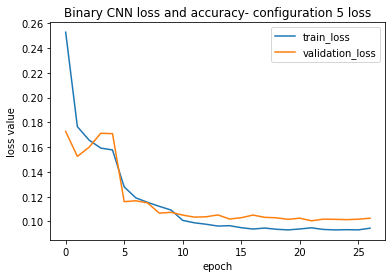

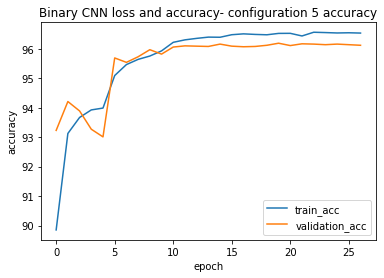

In [59]:
dropout_p = best_dropout_p
learning_rate = best_learning_rate
alpha = best_weight_decay 

model_binary_conv_conf5 = BinaryConvModel_conf3(dropout_p=dropout_p)
model_binary_conv_conf5 = model_binary_conv_conf5.to(device)

optimizer_conf5 = torch.optim.Adam(model_binary_conv_conf5.parameters(), lr=learning_rate, weight_decay=alpha)

n_epochs = 50

loss_fn_conf5 = nn.CrossEntropyLoss()
scheduler = torch.optim.lr_scheduler.StepLR(optimizer=optimizer_conf5, step_size=5, gamma=0.1)

Start = time.time()
train_losses_conf5, train_accuracies_conf5, val_losses_conf5, val_accuracies_conf5 = train_conf5(model_binary_conv_conf5, train_dataloader_conf2, val_dataloader_conf2, optimizer_conf5, n_epochs, loss_fn_conf5, scheduler)
End = time.time()
print("run time is={:f}".format(End-Start))

plot_fnc(train_losses_conf5, val_losses_conf5, train_accuracies_conf5, val_accuracies_conf5,"Binary CNN loss and accuracy- configuration 5","train","validation")

In [60]:
torch.save(model_binary_conv_conf5.state_dict(), 'model_tmp_conf5.ckpt')
torch.save(model_binary_conv_conf5.state_dict(), 'model_conf5.ckpt')

model_instance_list.append(model_binary_conv_conf5)
model_file_list.append('model_conf5.ckpt')
best_val_loss.append(val_losses_conf5[-1])

## Applying best model
Using your best model, run the multi-scale detection on the 4 full images
from point 2 and one image of your choice. Find a good threshold and
plot the detection results.

In [61]:

best_loss = np.inf
for idx in range(len(best_val_loss)):
  if(best_val_loss[idx] < best_loss):
    best_loss_idx = idx
    
best_model_file = model_file_list[idx]
best_model_instance = model_instance_list[idx]

print(best_model_file)

model_conf5.ckpt


In [62]:
model_binary_conv_conf5.load_state_dict(torch.load('model_conf5.ckpt'))

<All keys matched successfully>

###Threshold = nms=True

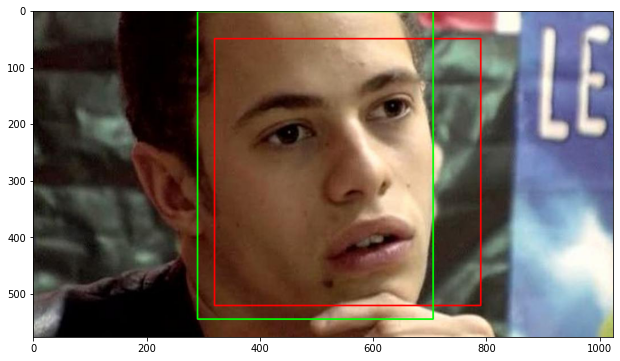

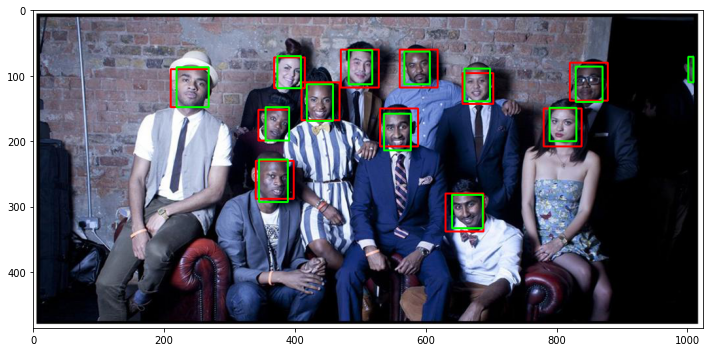

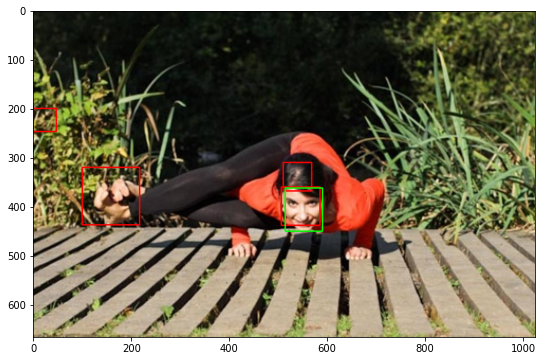

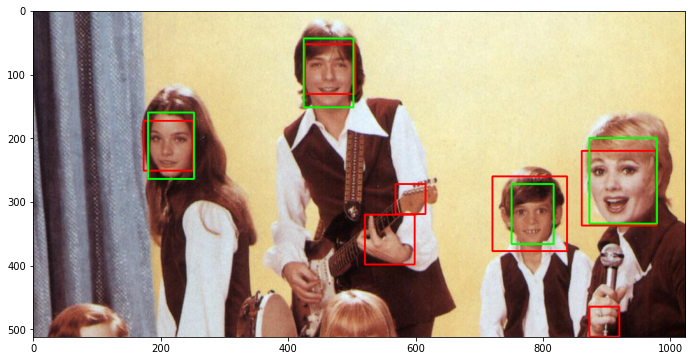

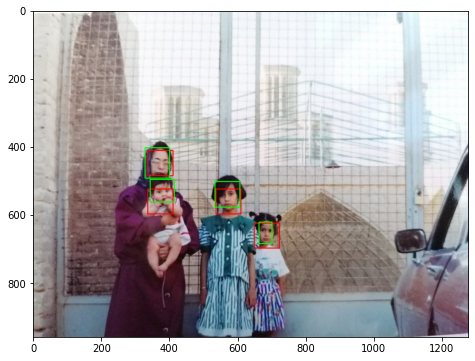

In [79]:
full_conv_detector = FullyConvolutionalDetector(model_binary_conv_conf5,threshold=0.99)
images, boxes = read_images("/content/full_images_tsk3", "/content/full_boxes_tsk3")

N=len(images)

for i in range(N):

  all_face_coordinates, all_face_probabilities = full_conv_detector.detect_multi_scale(images[i],nms_bool=True)
  draw_boxes_with_gt(images[i], all_face_coordinates, gt_boxes=boxes[i])
